<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTVN/ML_T3_BTVN_B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc: (45211, 17)
5 dong dau:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  

Phan bo nhan:
y
no     39922
yes     5289
Name: count, dtype: int64
Gia tr

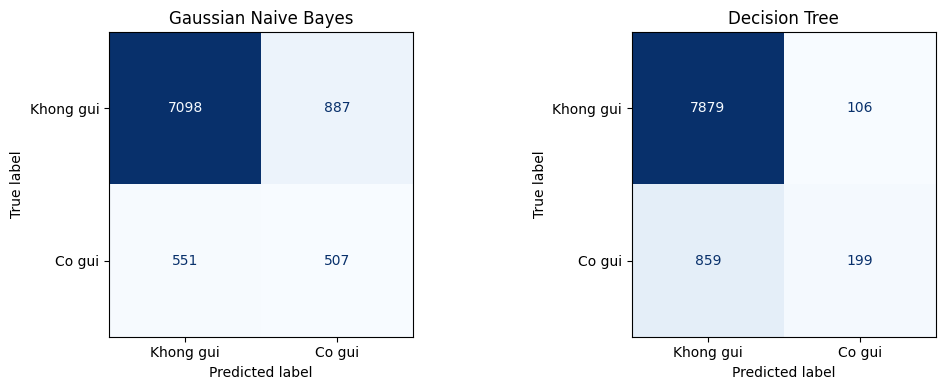


BANG SO SANH:
             Mo hinh  Accuracy  Precision  Recall     F1
Gaussian Naive Bayes    0.8410     0.3637  0.4792 0.4135
       Decision Tree    0.8933     0.6525  0.1881 0.2920


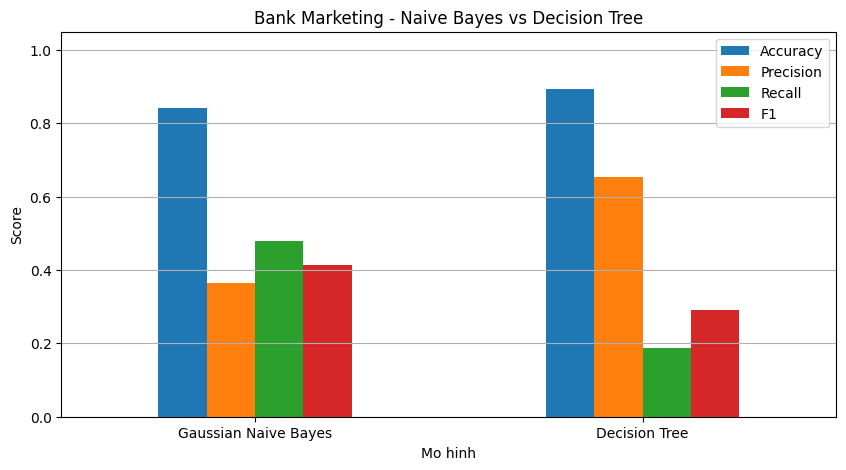


Mo hinh co Accuracy cao hon:
Decision Tree


In [1]:

import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

# 1. Tai Bank Marketing tu UCI
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(url, timeout=90) as response:
    raw = response.read()

# ZIP ben ngoai chua bank.zip
with zipfile.ZipFile(io.BytesIO(raw)) as outer:
    with zipfile.ZipFile(io.BytesIO(outer.read("bank.zip"))) as inner:
        with inner.open("bank-full.csv") as f:
            df = pd.read_csv(f, sep=";")

# 2. Kiem tra du lieu
print("Kich thuoc:", df.shape)
print("5 dong dau:")
print(df.head())
print("\nPhan bo nhan:")
print(df["y"].value_counts())
print("Gia tri thieu:", df.isna().sum().sum())

# 3. Xac dinh dac trung va nhan
# Loai duration de tranh dung thong tin sau cuoc goi
X = df.drop(columns=["y", "duration"])
y = (df["y"] == "yes").astype(int)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# 4. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Tien xu ly
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), cat_cols)
], sparse_threshold=0)

# 6. Tao hai mo hinh
models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        random_state=42
    )
}

results = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, algorithm) in zip(axes, models.items()):
    model = Pipeline([
        ("preprocess", preprocess),
        ("model", algorithm)
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)

    results.append({
        "Mo hinh": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

    print("\nMO HINH:", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)
    print(classification_report(
        y_test, pred,
        target_names=["Khong gui", "Co gui"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Khong gui", "Co gui"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 7. Bang so sanh
result_df = pd.DataFrame(results)
print("\nBANG SO SANH:")
print(result_df.round(4).to_string(index=False))

# 8. Bieu do
result_df.plot(
    x="Mo hinh",
    y=["Accuracy", "Precision", "Recall", "F1"],
    kind="bar",
    figsize=(10, 5)
)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Bank Marketing - Naive Bayes vs Decision Tree")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

print("\nMo hinh co Accuracy cao hon:")
print(result_df.loc[result_df["Accuracy"].idxmax(), "Mo hinh"])
